# Week 5 — Machine Learning Assignments
## Assignments 51–52: Linear Regression and Logistic Regression

Install the packages in the VS Code terminal:
```bash
python -m pip install numpy pandas scikit-learn matplotlib
```


## Assignment 51 — Linear Regression with scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Feature (X): study hours; target (y): exam score
X = np.array([1, 2, 2.5, 3, 4, 4.5, 5, 6, 7, 8], dtype=float).reshape(-1, 1)
y = np.array([35, 40, 45, 50, 58, 62, 65, 72, 80, 88], dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Slope (coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R²:", r2_score(y_test, predictions))

new_hours = np.array([[5.5]])
print("Predicted score for 5.5 study hours:", model.predict(new_hours)[0])

Slope (coefficient): 7.5984848484848495
Intercept: 27.08143939393939
MAE: 1.2746212121212182
RMSE: 1.6224208270331177
R²: 0.9934193766500229
Predicted score for 5.5 study hours: 68.87310606060606


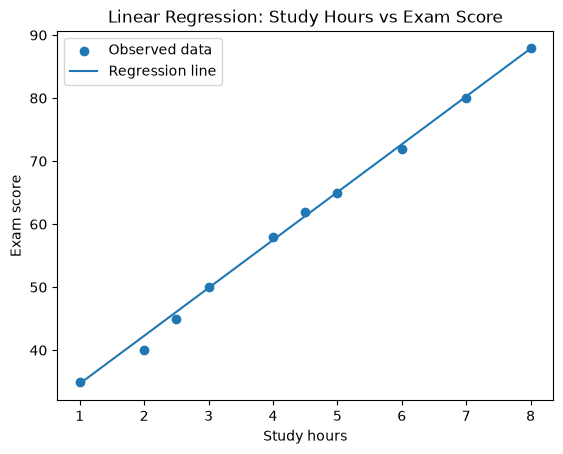

In [2]:
plt.scatter(X, y, label="Observed data")
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_line, model.predict(x_line), label="Regression line")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Linear Regression: Study Hours vs Exam Score")
plt.legend()
plt.show()

## Assignment 52 — Logistic Regression

In [3]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification report:\n")
print(classification_report(y_test, predictions, target_names=iris.target_names))
print("Confusion matrix:\n", confusion_matrix(y_test, predictions))

Accuracy: 0.9333333333333333

Classification report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [4]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)
predicted_class = model.predict(new_flower)[0]
probabilities = model.predict_proba(new_flower)[0]

print("Features:", iris.feature_names)
print("Predicted species:", iris.target_names[predicted_class])
print("Class probabilities:")
for name, probability in zip(iris.target_names, probabilities):
    print(f"{name}: {probability:.3f}")

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Predicted species: setosa
Class probabilities:
setosa: 0.981
versicolor: 0.019
virginica: 0.000
